In [9]:
import pandas as pd
from src.utils.path import DATA_DIR, CONFIG_DIR
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_validate
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from sklearn.linear_model import LogisticRegression
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer


# Load data

In [ ]:

cols = [
    "applicant_sex",
    "income",
    "loan_amount",
    "loan_purpose",
    "lien_status",
    "loan_type",
    "derived_race",
    "action_taken" #Target
]
df_2023 = pd.read_csv(f"{DATA_DIR}/raw/state_NY_2023.csv")
df_2023 = df_2023[cols].dropna(subset=cols)

df_2024 = pd.read_csv(f"{DATA_DIR}/raw/state_NY_2024.csv")
df_2024 = df_2024[cols].dropna(subset=cols)


# Preprocess

### Binary encoding derived_race
Black or African American: 1,
White: 0

In [4]:
target_races = ['Black or African American', 'White']
race_mapping = {'Black or African American': 1, 'White': 0}
df_2023 = df_2023[df_2023['derived_race'].isin(target_races)]
df_2024 = df_2024[df_2024['derived_race'].isin(target_races)]
df_2023['derived_race'] = df_2023['derived_race'].map({
    'Black or African American': 1,
    'White': 0
})
df_2024['derived_race'] = df_2024['derived_race'].map({
    'Black or African American': 1,
    'White': 0
})


In [5]:
df_2023 = df_2023[df_2023["action_taken"].isin([1, 2, 3])]
df_2024 = df_2024[df_2024["action_taken"].isin([1, 2, 3])]
df_2023["action_taken"] = df_2023["action_taken"].map({
    1: 0,  # Accepted
    2: 0,  # Accepted
    3: 1   # Denied
})

df_2024["action_taken"] = df_2024["action_taken"].map({
    1: 0,  # Accepted
    2: 0,  # Accepted
    3: 1   # Denied
})

# Đưa về pp chuẩn

In [6]:
# Cách viết Sign Log: giữ nguyên dấu âm/dương và log trị tuyệt đối
df_2023["income"] = np.sign(df_2023["income"]) * np.log1p(np.abs(df_2023["income"]))
df_2023["loan_amount"] = np.log1p(df_2023["loan_amount"])
df_2024["income"] = np.sign(df_2024["income"]) * np.log1p(np.abs(df_2024["income"]))
df_2023["loan_amount"] = np.log1p(df_2023["loan_amount"])



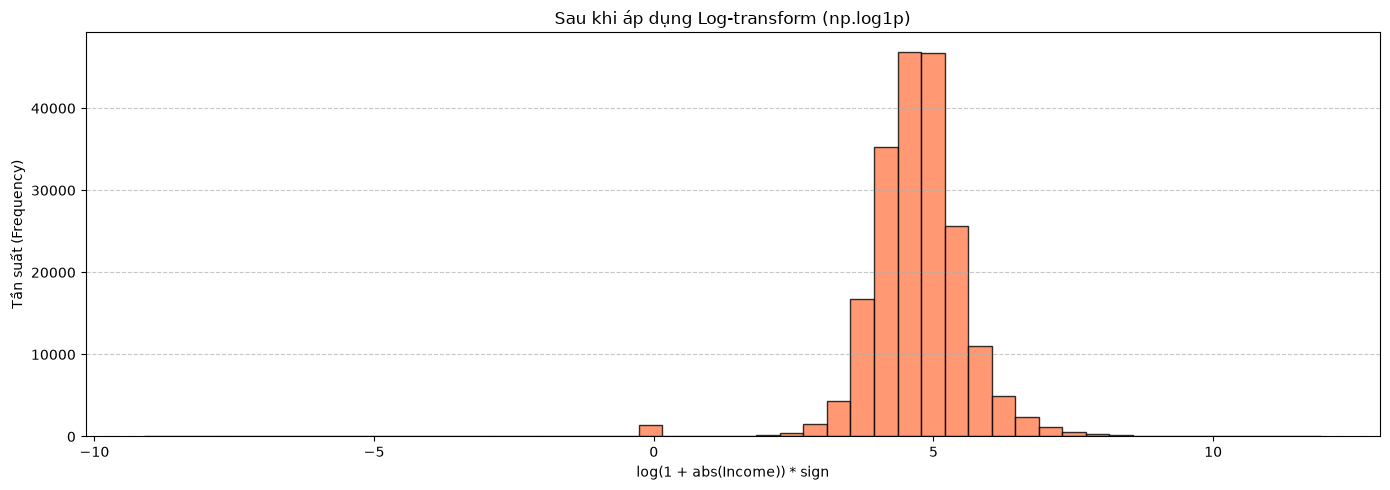

In [7]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 1, figsize=(14, 5))
axes.hist(df_2023["income"], bins=50, color='coral', edgecolor='black', alpha=0.8)
axes.set_title('Sau khi áp dụng Log-transform (np.log1p)')
axes.set_xlabel('log(1 + abs(Income)) * sign')
axes.set_ylabel('Tần suất (Frequency)')
axes.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    df_2023.drop(columns="action_taken"), df_2023["action_taken"],
    test_size=0.2, random_state=42)

In [15]:
import mlflow
import mlflow.sklearn

run_name = "RF_Impute_StandardScale_5Fold"

with mlflow.start_run(run_name=run_name):
    # Thiết lập tham số
    n_splits = 5
    n_estimators = 150
    max_depth = 6
    
    # A. Log Parameters (Ghi lại cấu hình thí nghiệm)
    mlflow.log_param("test_size", 0.2)
    mlflow.log_param("cv_splits", n_splits)
    mlflow.log_param("model_type", "RandomForest")
    mlflow.log_param("n_estimators", n_estimators)
    mlflow.log_param("max_depth", max_depth)

    # B. Xây dựng Pipeline chuẩn chống rò rỉ dữ liệu
    pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('classifier', RandomForestClassifier(
            n_estimators=n_estimators, 
            max_depth=max_depth, 
            random_state=42
        ))
    ])

    # C. Đánh giá nội bộ bằng Stratified K-Fold trên tập Train
    cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
    cv_results = cross_validate(
        pipeline, X_train, y_train, 
        cv=cv, 
        scoring=['accuracy', 'f1'], 
        return_train_score=True
    )

    # Ghi nhận kết quả Cross-Validation (Mean & Std)
    mlflow.log_metric("cv_train_acc_mean", np.mean(cv_results['train_accuracy']))
    mlflow.log_metric("cv_val_acc_mean", np.mean(cv_results['test_accuracy']))
    mlflow.log_metric("cv_val_acc_std", np.std(cv_results['test_accuracy']))
    mlflow.log_metric("cv_val_f1_mean", np.mean(cv_results['test_f1']))

    # D. Huấn luyện lại trên toàn bộ X_train
    pipeline.fit(X_train, y_train)

    # E. Chấm điểm trên Test Set độc lập
    y_pred = pipeline.predict(X_test)
    test_acc = accuracy_score(y_test, y_pred)
    test_f1 = f1_score(y_test, y_pred)

    mlflow.log_metric("final_test_accuracy", test_acc)
    mlflow.log_metric("final_test_f1", test_f1)

    # F. Đóng gói và lưu toàn bộ Pipeline làm Model Artifact
    mlflow.sklearn.log_model(
        sk_model=pipeline,
        artifact_path="pipeline_model",
        registered_model_name="Customer_Churn_Model",
        serialization_format="cloudpickle"  # Đưa thẳng vào Model Registry nếu muốn
    )

    print(f"Hoàn thành Run '{run_name}'!")
    print(f"-> Điểm CV Val Acc: {np.mean(cv_results['test_accuracy']):.4f}")
    print(f"-> Điểm Final Test Acc: {test_acc:.4f}")

2026/09/20 10:36:11 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/09/20 10:36:11 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Hoàn thành Run 'RF_Impute_StandardScale_5Fold'!
-> Điểm CV Val Acc: 0.7746
-> Điểm Final Test Acc: 0.7724


Successfully registered model 'Customer_Churn_Model'.
Created version '1' of model 'Customer_Churn_Model'.
